In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("olist_customers_dataset.csv")

In [4]:
df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
df.shape

(99441, 5)

In [6]:
total_row = df.shape[0]
total_row

99441

In [8]:
total_column = df.shape[1]
total_column

5

### Question 2. How many unique customers are present in the dataset?

In [7]:
unique_customers = df["customer_id"].nunique
unique_customers

<bound method IndexOpsMixin.nunique of 0        06b8999e2fba1a1fbc88172c00ba8bc7
1        18955e83d337fd6b2def6b18a428ac77
2        4e7b3e00288586ebd08712fdd0374a03
3        b2b6027bc5c5109e529d4dc6358b12c3
4        4f2d8ab171c80ec8364f7c12e35b23ad
                       ...               
99436    17ddf5dd5d51696bb3d7c6291687be6f
99437    e7b71a9017aa05c9a7fd292d714858e8
99438    5e28dfe12db7fb50a4b2f691faecea5e
99439    56b18e2166679b8a959d72dd06da27f9
99440    274fa6071e5e17fe303b9748641082c8
Name: customer_id, Length: 99441, dtype: object>

### Question 3. What are the column names and their data types?

In [11]:
column_analysis = pd.DataFrame({
    "Column_Name": df.columns,
    "Data_Type": df.dtypes.values,
    "Non_Null_Count": df.notnull().sum().values,
    "Unique_Values": df.nunique().values
})

display(column_analysis)

,Column_Name,Data_Type,Non_Null_Count,Unique_Values
0,customer_id,object,99441,99441
1,customer_unique_id,object,99441,96096
2,customer_zip_code_prefix,int64,99441,14994
3,customer_city,object,99441,4119
4,customer_state,object,99441,27


In [18]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
99436    False
99437    False
99438    False
99439    False
99440    False
Length: 99441, dtype: bool

### Question 7. Which are the Top 10 cities with the highest number of customers?

In [22]:
city_customers = (df["customer_city"].value_counts().head(10))
city_customers

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64

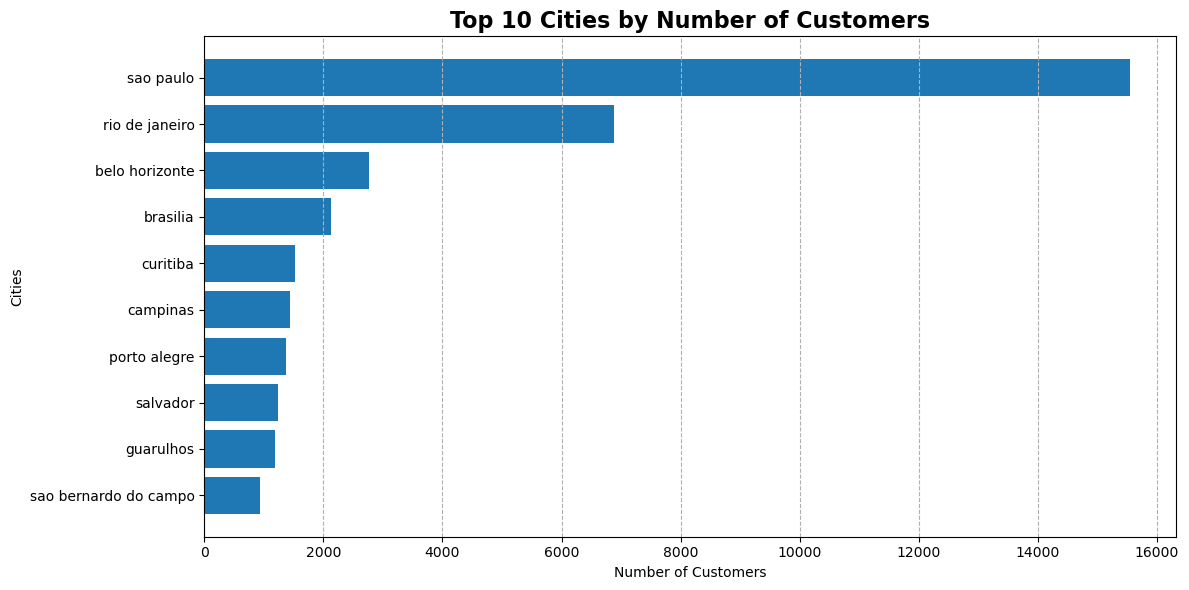

In [46]:
plt.figure(figsize=(12, 6))

plt.barh(
    city_customers.index[::-1],
    city_customers.values[::-1]
)

plt.title("Top 10 Cities by Number of Customers",
          fontsize=16, fontweight="bold")

plt.xlabel("Number of Customers")
plt.ylabel("Cities")

plt.grid(axis="x", linestyle="--")

plt.tight_layout()
plt.show()

### Which are the Top 10 States with the Highest Number of Customers?

In [38]:
state_customers = (
    df["customer_state"]
    .value_counts()
    .head(10)
)

state_customers

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64

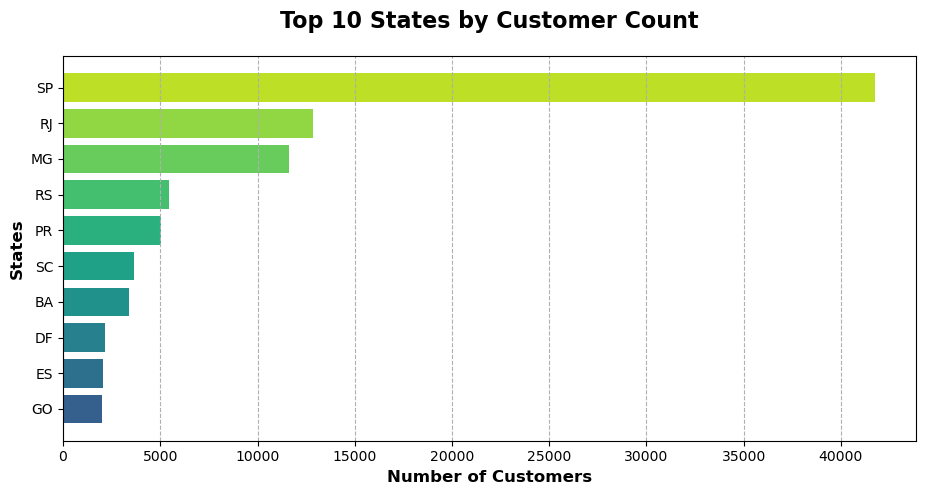

In [45]:
import numpy as np
plt.figure(figsize=(11, 5))

bars = plt.barh(
    state_customers.index[::-1],
    state_customers.values[::-1],
    color=colors
)

plt.title(
    "Top 10 States by Customer Count",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Number of Customers", fontsize=12,fontweight="bold")
plt.ylabel("States", fontsize=12,fontweight="bold")

plt.grid(axis="x", linestyle="--")

plt.show()

### What is the percentage distribution of customers across the top 5 states?

In [48]:
state_distribution = df["customer_state"].value_counts()

top_5_states = state_distribution.head(5)

other_states = state_distribution.iloc[5:].sum()

pie_data = pd.concat([
    top_5_states,
    pd.Series({"Others": other_states})
])

pie_data

SP        41746
RJ        12852
MG        11635
RS         5466
PR         5045
Others    22697
dtype: int64

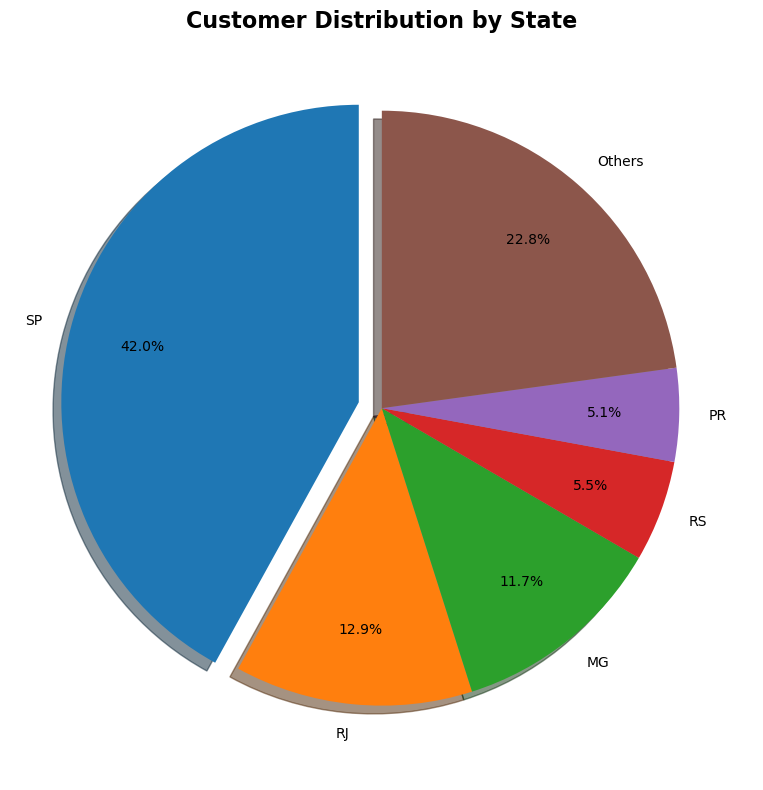

In [49]:
plt.figure(figsize=(10, 8))

plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.08, 0, 0, 0, 0, 0],
    shadow=True,
    pctdistance=0.75
)

plt.title(
    "Customer Distribution by State",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [8]:
df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### Customer Distribution by State

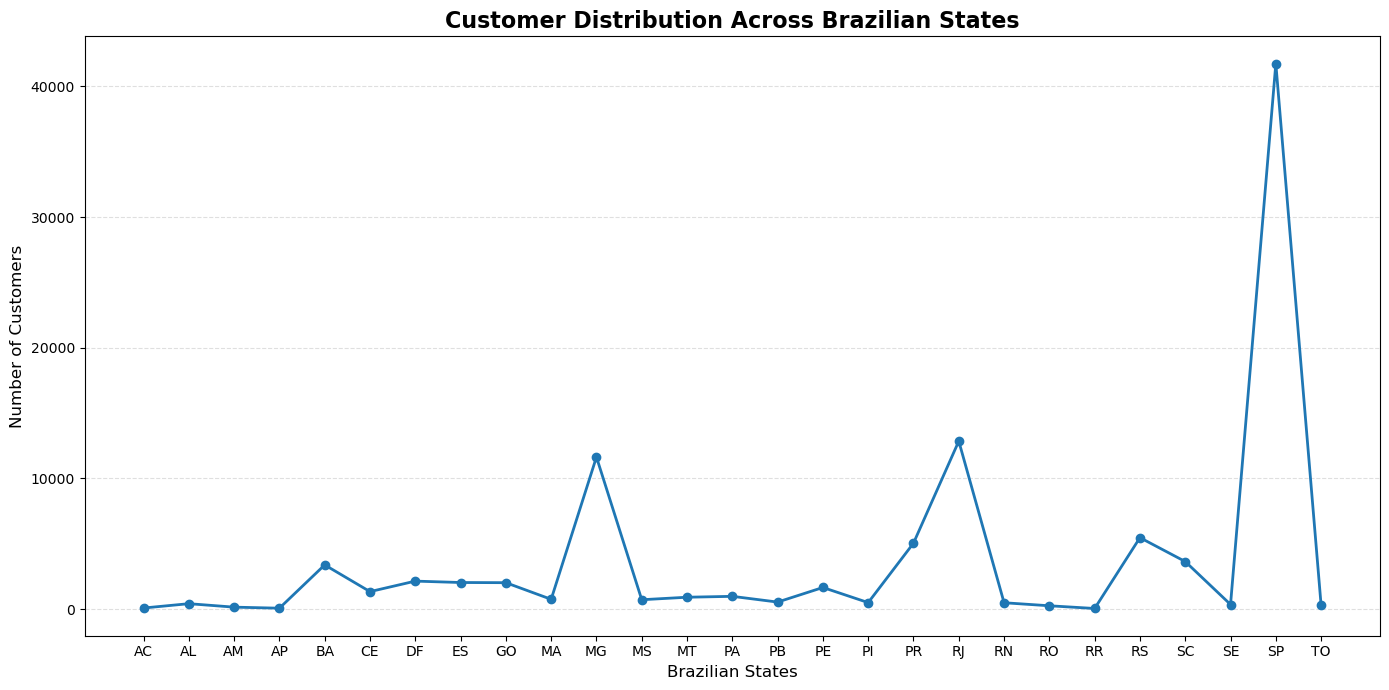

In [10]:
# Count customers in each state
state_trend = df["customer_state"].value_counts()

# Sort states alphabetically for a geographical category sequence
state_trend = state_trend.sort_index()

# Create figure
plt.figure(figsize=(14, 7))

# Create line chart
plt.plot(
    state_trend.index,
    state_trend.values,
    marker="o",
    linestyle="-",
    linewidth=2,
    markersize=6
)

# Add title and axis labels
plt.title(
    "Customer Distribution Across Brazilian States",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Brazilian States", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

# Add grid
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()